# Proyecto de series de tiempo: pronostico de ventas

Objetivo: describir la serie diaria de ventas de la empresa, responder si tiene tendencia, si es estacionaria y si tiene ruido, entrenar un ARIMA con los datos de entrenamiento, evaluarlo en un conjunto de prueba y guardarlo.

Reglas de trabajo: en una serie de tiempo el orden importa, asi que el conjunto de prueba son los ultimos dias (nunca una muestra aleatoria). Todo lo que se elige (parametros, diferenciacion) se decide solo con el entrenamiento; el conjunto de prueba solo se usa para evaluar. Se compara siempre contra una linea base ingenua, porque un modelo que no la supera no aporta valor.

## Bloque 1: carga y estructura de la serie

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv("../sales.csv")

print("Filas y columnas:", datos.shape)
print("Nulos en total:", int(datos.isna().sum().sum()))
print("Filas duplicadas:", int(datos.duplicated().sum()))
print("Tipos:")
print(datos.dtypes.to_string())
print()
print(datos.head(3).to_string())
print(datos.tail(3).to_string())

Filas y columnas: (366, 2)
Nulos en total: 0
Filas duplicadas: 0
Tipos:
date         str
sales    float64

                         date      sales
0  2022-09-03 17:10:08.079328  55.292157
1  2022-09-04 17:10:08.079328  53.803211
2  2022-09-05 17:10:08.079328  58.141693
                           date        sales
363  2023-09-01 17:10:08.079328   995.814415
364  2023-09-02 17:10:08.079328   997.350214
365  2023-09-03 17:10:08.079328  1000.482785


La fecha viene como texto con una hora fija (17:10:08) que no aporta informacion: es la hora en que se genero el archivo. Se convierte a fecha, se descarta la hora y se usa como indice. Despues se comprueba que no falte ningun dia ni haya fechas repetidas, porque `ARIMA` supone observaciones igualmente espaciadas.

In [2]:
datos["date"] = pd.to_datetime(datos["date"])
print("Horas distintas en la columna:", datos["date"].dt.time.nunique())

ventas = datos.set_index(datos["date"].dt.normalize())["sales"].rename("ventas")
ventas.index.name = "fecha"

print("Periodo:", ventas.index.min().date(), "->", ventas.index.max().date())
print("Fechas repetidas:", int(ventas.index.duplicated().sum()))
print("Indice ordenado:", ventas.index.is_monotonic_increasing)
print("Frecuencia inferida:", ventas.index.inferred_freq)

ventas = ventas.asfreq("D")
print("Dias faltantes tras asfreq('D'):", int(ventas.isna().sum()))
print("Total de dias:", len(ventas))
print()
print(ventas.describe().round(2).to_string())

Horas distintas en la columna: 1
Periodo: 2022-09-03 -> 2023-09-03
Fechas repetidas: 0
Indice ordenado: True
Frecuencia inferida: D
Dias faltantes tras asfreq('D'): 0
Total de dias: 366

count     366.00
mean      524.96
std       275.09
min        53.80
25%       290.19
50%       520.70
75%       763.29
max      1000.48


/tmp/ipykernel_16606/1119504887.py:10: Pandas4Warning: A future version of pandas will return a BaseOffset object instead of a string from inferred_freq. Use pd.set_option('future.infer_freq_returns_offset', True) to get the future behavior, or set to False to keep the old behavior and silence this warning. To preserve the string representation, use ``inferred_freq.freqstr``.
  print("Frecuencia inferida:", ventas.index.inferred_freq)


Primer vistazo a la serie completa y a su variacion de un dia a otro (la diferencia diaria), que ayuda a ver si el crecimiento es parejo.

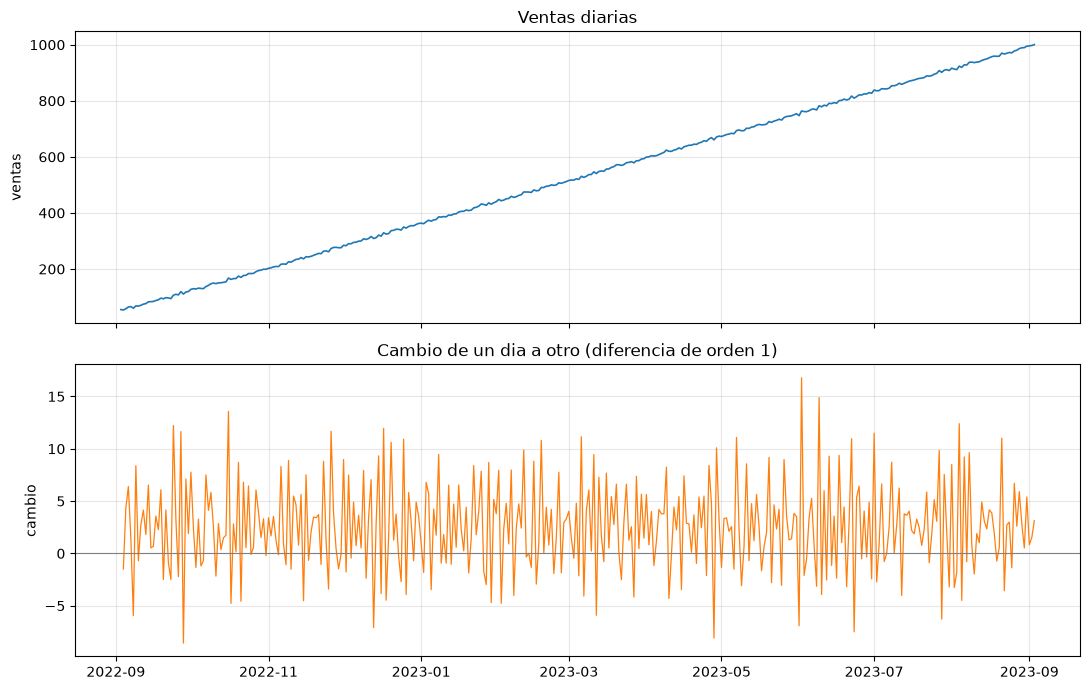

Cambio diario medio: 2.59
Desviacion del cambio diario: 4.259
Primer valor: 55.29 | ultimo valor: 1000.48


In [3]:
fig, ejes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ejes[0].plot(ventas.index, ventas.values, color="tab:blue", linewidth=1.2)
ejes[0].set_title("Ventas diarias")
ejes[0].set_ylabel("ventas")
ejes[0].grid(alpha=0.3)

diferencia = ventas.diff()
ejes[1].plot(diferencia.index, diferencia.values, color="tab:orange", linewidth=0.9)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_title("Cambio de un dia a otro (diferencia de orden 1)")
ejes[1].set_ylabel("cambio")
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Cambio diario medio:", round(float(diferencia.mean()), 3))
print("Desviacion del cambio diario:", round(float(diferencia.std()), 3))
print("Primer valor:", round(float(ventas.iloc[0]), 2), "| ultimo valor:", round(float(ventas.iloc[-1]), 2))

## Bloque 2: analisis de la serie (frecuencia, tendencia, estacionariedad y ruido)

Este bloque es descriptivo: usa toda la serie para entenderla y responder las cuatro preguntas del enunciado. Ninguna decision del modelo se toma aqui; los parametros del ARIMA se eligen mas adelante solo con el entrenamiento.

**Pregunta 1, el "tensor" de la serie.** En el enunciado "tensor" es la unidad minima de tiempo con datos, es decir, la frecuencia. En el Bloque 1 se comprobo que hay un dato por dia, sin huecos ni fechas repetidas (frecuencia `D`, 366 dias). Respuesta: **diaria**.

**Pregunta 2, la tendencia.** Se ajusta una recta a la serie y se mira cuanto de la variacion explica, junto con una media movil de 30 dias.

Pendiente de la recta (ventas por dia): 2.6
Valor de la recta el primer dia: 50.47
R2 de la recta: 0.99988
Crecimiento estimado en el periodo: 949.0


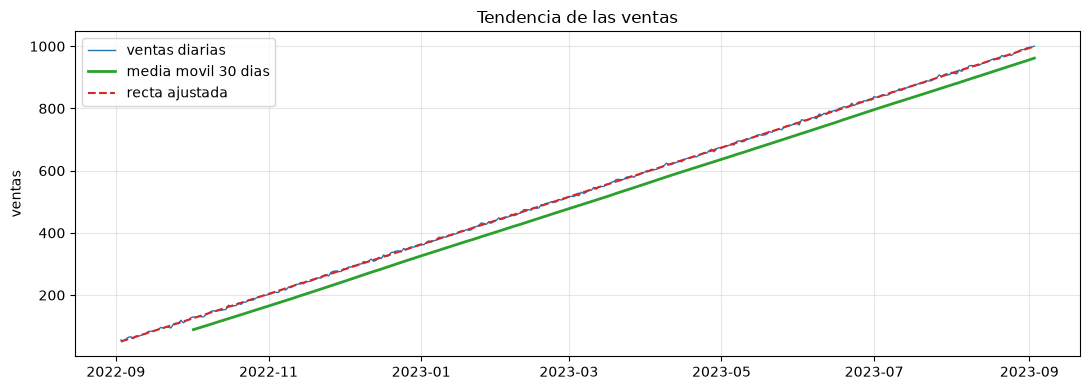

In [4]:
dias = np.arange(len(ventas))
pendiente, intercepto = np.polyfit(dias, ventas.values, 1)
recta = pd.Series(intercepto + pendiente * dias, index=ventas.index)
residuo = ventas - recta

r2 = 1 - residuo.var() / ventas.var()
print("Pendiente de la recta (ventas por dia):", round(float(pendiente), 3))
print("Valor de la recta el primer dia:", round(float(intercepto), 2))
print("R2 de la recta:", round(float(r2), 5))
print("Crecimiento estimado en el periodo:", round(float(pendiente * (len(ventas) - 1)), 1))

fig, eje = plt.subplots(figsize=(11, 4))
eje.plot(ventas.index, ventas.values, color="tab:blue", linewidth=1.0, label="ventas diarias")
eje.plot(ventas.rolling(30).mean(), color="tab:green", linewidth=2, label="media movil 30 dias")
eje.plot(recta.index, recta.values, color="tab:red", linestyle="--", linewidth=1.5, label="recta ajustada")
eje.set_title("Tendencia de las ventas")
eje.set_ylabel("ventas")
eje.legend()
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Pregunta 3, estacionariedad.** Una serie es estacionaria si su media y su varianza no cambian con el tiempo. Aqui la media sube sin parar, asi que se espera que no lo sea. Se confirma con el test de Dickey-Fuller aumentado (ADF), cuya hipotesis nula es que la serie **no** es estacionaria: un p-valor menor que 0,05 permite rechazarla (es decir, concluir que si es estacionaria) y un p-valor alto no. Se aplica a la serie, a su primera diferencia (cambio de un dia a otro) y al residuo de la recta.

In [5]:
from statsmodels.tsa.stattools import adfuller

def adf(serie, nombre):
    estadistico, p, rezagos, _, criticos, _ = adfuller(serie.dropna(), autolag="AIC", result_object=False)
    conclusion = "estacionaria (se rechaza la nula)" if p < 0.05 else "NO estacionaria (no se rechaza la nula)"
    print(f"{nombre:<28} ADF={estadistico:8.3f}  p={p:.4f}  rezagos={rezagos:<3} -> {conclusion}")

adf(ventas, "serie original")
adf(ventas.diff(), "primera diferencia")
adf(residuo, "residuo de la recta")

serie original               ADF=   0.545  p=0.9862  rezagos=13  -> NO estacionaria (no se rechaza la nula)
primera diferencia           ADF=  -9.430  p=0.0000  rezagos=12  -> estacionaria (se rechaza la nula)
residuo de la recta          ADF= -19.924  p=0.0000  rezagos=0   -> estacionaria (se rechaza la nula)


**Pregunta 4, variabilidad y ruido.** Se mira el residuo (lo que queda despues de quitar la recta): su tamano, si cambia con el tiempo y si tiene memoria (autocorrelacion). Tambien se revisa si hay estacionalidad semanal, comparando el residuo medio de cada dia de la semana con el tamano del ruido.

Desviacion del residuo: 2.95 | como % de la media de ventas: 0.56 %
Desviacion del residuo en el primer tercio: 3.15 | ultimo tercio: 2.93
Autocorrelacion del residuo (rezagos 1 a 7): [-0.04  0.05  0.05 -0.04  0.02 -0.04  0.14]
Banda aproximada de ruido blanco (+/-): 0.1
Residuo medio por dia de la semana:
lun    0.55
mar    0.14
mie   -0.20
jue   -0.50
vie   -1.30
sab    0.66
dom    0.63


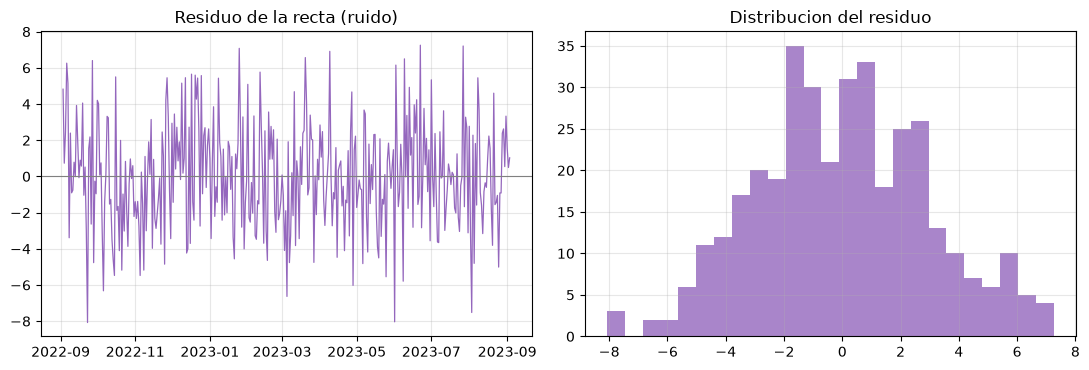

In [6]:
from statsmodels.tsa.stattools import acf

print("Desviacion del residuo:", round(float(residuo.std()), 2),
      "| como % de la media de ventas:", round(float(residuo.std() / ventas.mean() * 100), 2), "%")
print("Desviacion del residuo en el primer tercio:", round(float(residuo.iloc[:122].std()), 2),
      "| ultimo tercio:", round(float(residuo.iloc[-122:].std()), 2))

auto = acf(residuo, nlags=7)
print("Autocorrelacion del residuo (rezagos 1 a 7):", np.round(auto[1:], 2))
print("Banda aproximada de ruido blanco (+/-):", round(1.96 / np.sqrt(len(residuo)), 2))

por_dia = residuo.groupby(residuo.index.map(lambda f: f.weekday())).mean()
por_dia.index = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]
print("Residuo medio por dia de la semana:")
print(por_dia.round(2).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].plot(residuo.index, residuo.values, color="tab:purple", linewidth=0.9)
ejes[0].axhline(0, color="gray", linewidth=0.8)
ejes[0].set_title("Residuo de la recta (ruido)")
ejes[0].grid(alpha=0.3)
ejes[1].hist(residuo.values, bins=25, color="tab:purple", alpha=0.8)
ejes[1].set_title("Distribucion del residuo")
ejes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones del Bloque 2

1. **Tensor (frecuencia):** diaria, un dato por dia sin huecos.
2. **Tendencia:** hay una tendencia creciente y casi perfectamente lineal. Una recta de unas 2,6 ventas por dia explica el 99,99 % de la variacion (R2 = 0,99988) y la serie pasa de 55 a 1000 en el periodo. La media movil de 30 dias coincide con la recta.
3. **Estacionariedad:** la serie original **no** es estacionaria (ADF p = 0,986: no se rechaza la nula). Su primera diferencia **si** lo es (p < 0,001), asi que una sola diferenciacion (d = 1) basta. El residuo de la recta tambien es estacionario.
4. **Variabilidad y ruido:** hay ruido pero es pequeno y estable. El residuo tiene desviacion de 2,95 (0,56 % de la media), parecida en el primer tercio (3,15) y en el ultimo (2,93), asi que la variabilidad no crece con el nivel. Casi no tiene memoria (autocorrelaciones entre -0,04 y 0,05 en los rezagos 1 a 6, dentro de la banda de +/-0,10). Hay un indicio muy debil de efecto semanal (autocorrelacion 0,14 en el rezago 7 y viernes con -1,3), pero es del orden de la mitad del ruido y no justifica un modelo estacional.

Consecuencia para el modelo: la serie es "recta mas ruido". Un ARIMA con una diferenciacion y una constante (la deriva, que es la pendiente de 2,6) deberia captarla. Sin esa constante el pronostico quedaria plano, porque tras diferenciar la media deja de ser cero.

## Bloque 3: particion por fecha y lineas base

El conjunto de prueba son los **ultimos 60 dias** (unos dos meses, el horizonte que importa para planificar la bodega). El entrenamiento es todo lo anterior. A partir de aqui, nada de lo que se decida puede mirar el conjunto de prueba.

Antes de entrenar el ARIMA se fijan dos pronosticos ingenuos con los que compararlo, porque un modelo solo aporta valor si los supera:

- **Ultimo valor:** repetir el ultimo dia del entrenamiento (ignora la tendencia).
- **Deriva:** el ultimo valor mas la pendiente media diaria del entrenamiento por cada dia que pasa (una recta extrapolada).

Las metricas son MAE (error absoluto medio), RMSE (penaliza mas los errores grandes) y MAPE (error porcentual medio).

Entrenamiento: 2022-09-03 -> 2023-07-05 | 306 dias
Prueba:        2023-07-06 -> 2023-09-03 | 60 dias
Proporcion de prueba: 16.4 %
Se solapan las fechas: False

Pendiente media diaria del entrenamiento: 2.581
                MAE   RMSE  MAPE %
ultimo valor  80.15  92.12    8.46
deriva         2.44   3.10    0.26


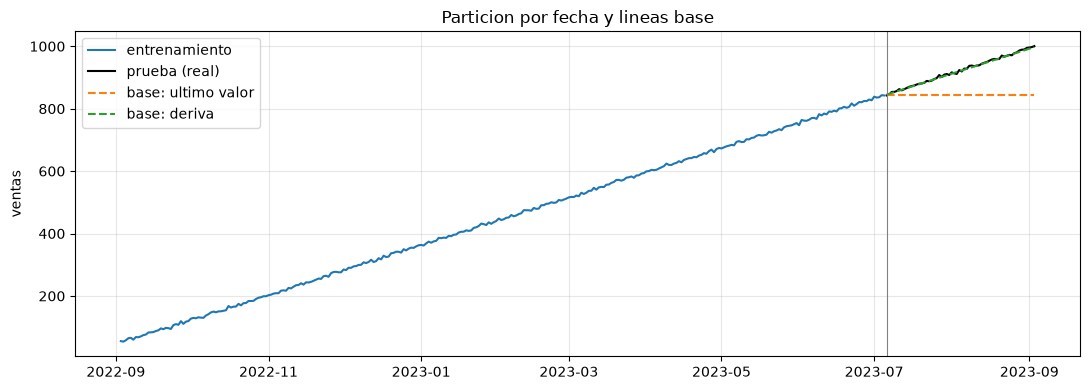

In [7]:
DIAS_TEST = 60
entrenamiento = ventas.iloc[:-DIAS_TEST]
prueba = ventas.iloc[-DIAS_TEST:]

print("Entrenamiento:", entrenamiento.index.min().date(), "->", entrenamiento.index.max().date(), "|", len(entrenamiento), "dias")
print("Prueba:       ", prueba.index.min().date(), "->", prueba.index.max().date(), "|", len(prueba), "dias")
print("Proporcion de prueba:", round(len(prueba) / len(ventas) * 100, 1), "%")
print("Se solapan las fechas:", bool(entrenamiento.index.intersection(prueba.index).size))

def metricas(real, pred):
    error = real.values - np.asarray(pred)
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    mape = np.mean(np.abs(error) / real.values) * 100
    return {"MAE": round(float(mae), 2), "RMSE": round(float(rmse), 2), "MAPE %": round(float(mape), 2)}

pred_ultimo = np.repeat(entrenamiento.iloc[-1], len(prueba))
pendiente_train = (entrenamiento.iloc[-1] - entrenamiento.iloc[0]) / (len(entrenamiento) - 1)
pred_deriva = entrenamiento.iloc[-1] + pendiente_train * np.arange(1, len(prueba) + 1)

print()
print("Pendiente media diaria del entrenamiento:", round(float(pendiente_train), 3))
tabla = pd.DataFrame({"ultimo valor": metricas(prueba, pred_ultimo), "deriva": metricas(prueba, pred_deriva)}).T
print(tabla.to_string())

fig, eje = plt.subplots(figsize=(11, 4))
eje.plot(entrenamiento.index, entrenamiento.values, color="tab:blue", label="entrenamiento")
eje.plot(prueba.index, prueba.values, color="black", label="prueba (real)")
eje.plot(prueba.index, pred_ultimo, color="tab:orange", linestyle="--", label="base: ultimo valor")
eje.plot(prueba.index, pred_deriva, color="tab:green", linestyle="--", label="base: deriva")
eje.axvline(prueba.index[0], color="gray", linewidth=0.8)
eje.set_title("Particion por fecha y lineas base")
eje.set_ylabel("ventas")
eje.legend()
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones del Bloque 3

El entrenamiento tiene 306 dias y la prueba los 60 ultimos, sin solapamiento. Repetir el ultimo valor falla mucho (MAE 80, RMSE 92, MAPE 8,5 %) porque ignora que la serie sube unas 2,6 ventas cada dia. La deriva casi no falla (MAE 2,44, RMSE 3,10, MAPE 0,26 %) y queda cerca del nivel de ruido de la serie (desviacion de 2,95 en el residuo), que ningun modelo puede bajar. Esa es la vara con la que se medira al ARIMA.

## Bloque 4: eleccion de los parametros del ARIMA (solo con el entrenamiento)

Un `ARIMA(p, d, q)` tiene tres numeros: `d` es cuantas veces se diferencia la serie para volverla estacionaria, `p` cuantos valores pasados de la serie usa (parte autorregresiva) y `q` cuantos errores pasados usa (parte de media movil). Como la serie sube sin parar, tras diferenciar queda una media distinta de cero (la pendiente), asi que se incluye una constante con `trend="t"`; sin ella el pronostico seria plano y fallaria como el ultimo valor.

Pasos, todos solo con el entrenamiento:

1. Confirmar `d` repitiendo el test ADF en el entrenamiento.
2. Probar todas las combinaciones con `p` y `q` entre 0 y 3 (16 modelos) y compararlas con AIC y BIC. Ambos miden que tan bien ajusta el modelo penalizando que tenga mas parametros; menor es mejor, y el BIC penaliza mas la complejidad.
3. Regla de seleccion, fijada antes de ver el resultado: elegir el menor AIC, pero si hay modelos a menos de 2 puntos de AIC del mejor (diferencia sin importancia practica), quedarse con el que tenga menos parametros.
4. Revisar que los residuos del modelo elegido parezcan ruido blanco (test de Ljung-Box: un p-valor alto indica que no queda informacion sin aprovechar).

In [8]:
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1) confirmar d solo con el entrenamiento
for nombre, serie in [("entrenamiento", entrenamiento), ("entrenamiento, 1a diferencia", entrenamiento.diff())]:
    estadistico, p, *_ = adfuller(serie.dropna(), autolag="AIC", result_object=False)
    print(f"{nombre:<30} ADF={estadistico:7.3f}  p={p:.4f}")

# 2) rejilla de modelos ARIMA(p, 1, q) con constante (deriva)
filas = []
for p in range(4):
    for q in range(4):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajuste = ARIMA(entrenamiento, order=(p, 1, q), trend="t").fit()
        filas.append({"p": p, "q": q, "parametros": p + q + 2, "AIC": ajuste.aic, "BIC": ajuste.bic})

rejilla = pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)
rejilla["dAIC"] = rejilla["AIC"] - rejilla["AIC"].min()
print()
print("Mejores 6 modelos por AIC:")
print(rejilla.head(6).round(2).to_string(index=False))
print()
print("Mejor modelo por BIC:", rejilla.sort_values("BIC").iloc[0][["p", "q"]].astype(int).to_dict())

entrenamiento                  ADF=  0.340  p=0.9791
entrenamiento, 1a diferencia   ADF=-12.910  p=0.0000



Mejores 6 modelos por AIC:
 p  q  parametros     AIC     BIC  dAIC
 0  2           4 1544.96 1559.84  0.00
 1  1           4 1545.06 1559.94  0.10
 0  1           3 1546.08 1557.24  1.12
 1  2           5 1546.61 1565.21  1.65
 0  3           5 1546.92 1565.52  1.96
 2  1           5 1546.95 1565.55  1.99

Mejor modelo por BIC: {'p': 0, 'q': 1}


In [9]:
# 3) regla: entre los modelos a menos de 2 puntos de AIC del mejor, el de menos parametros
candidatos = rejilla[rejilla["dAIC"] < 2].sort_values(["parametros", "AIC"])
elegido = candidatos.iloc[0]
P, Q = int(elegido["p"]), int(elegido["q"])
print("Candidatos a menos de 2 puntos de AIC:", [(int(a), 1, int(b)) for a, b in zip(candidatos["p"], candidatos["q"])])
print("Modelo elegido: ARIMA(%d, 1, %d) con constante" % (P, Q))

modelo = ARIMA(entrenamiento, order=(P, 1, Q), trend="t").fit()
print()
print("Parametros estimados:")
print(modelo.params.round(4).to_string())
print("Errores estandar:")
print(modelo.bse.round(4).to_string())

# 4) residuos del modelo (se omite el primero, que depende del valor inicial)
residuos = modelo.resid.iloc[1:]
lb = acorr_ljungbox(residuos, lags=[10, 20], return_df=True)
print()
print("Ljung-Box de los residuos (p alto = parecen ruido blanco):")
print(lb.round(3).to_string())
print("Desviacion de los residuos:", round(float(residuos.std()), 2))

Candidatos a menos de 2 puntos de AIC: [(0, 1, 1), (0, 1, 2), (1, 1, 1), (1, 1, 2), (0, 1, 3), (2, 1, 1)]
Modelo elegido: ARIMA(0, 1, 1) con constante

Parametros estimados:
x1        2.5991
ma.L1    -0.9450
sigma2    9.0631
Errores estandar:
x1        0.0102
ma.L1     0.0203
sigma2    0.7990

Ljung-Box de los residuos (p alto = parecen ruido blanco):
    lb_stat  lb_pvalue
10   11.717      0.304
20   21.319      0.379
Desviacion de los residuos: 3.03


### Conclusiones del Bloque 4

Con solo el entrenamiento, el ADF confirma d = 1 (serie original p = 0,979; primera diferencia p < 0,001). De los 16 modelos probados, el menor AIC es `ARIMA(0,1,2)`, pero lo separan solo 1,12 puntos de `ARIMA(0,1,1)`, una diferencia sin importancia practica, y el BIC tambien elige `(0,1,1)`. Por la regla fijada de antemano se elige **`ARIMA(0,1,1)` con constante**. Sus parametros son una deriva de 2,599 ventas por dia (error estandar 0,010) y un termino de media movil de -0,945. Un valor cercano a -1 es lo esperable cuando la serie es una recta mas ruido blanco: el modelo esta estimando esa recta. Los residuos parecen ruido blanco (Ljung-Box con p = 0,30 y 0,38), asi que el modelo no dejo estructura sin aprovechar.

## Bloque 5: evaluacion en el conjunto de prueba

Por primera vez se usa el conjunto de prueba. El modelo ajustado con el entrenamiento pronostica los 60 dias de prueba de una sola vez (sin ver ningun dato real de esos dias) y el pronostico se compara con lo ocurrido, junto con las dos lineas base. Ademas se calcula un intervalo de confianza del 95 % y se mide que proporcion de los dias reales cae dentro de el, que es lo que permite planificar la bodega con un margen.

Desempeno en los 60 dias de prueba:
                MAE   RMSE  MAPE %
ultimo valor  80.15  92.12    8.46
deriva         2.44   3.10    0.26
ARIMA(0,1,1)   2.26   2.80    0.25

Dias reales dentro del intervalo del 95 %: 58 de 60 -> 96.7 %
Ancho del intervalo: primer dia 11.8 | ultimo dia 12.8
Error medio (sesgo) del ARIMA: -0.75 | desviacion del error: 2.7


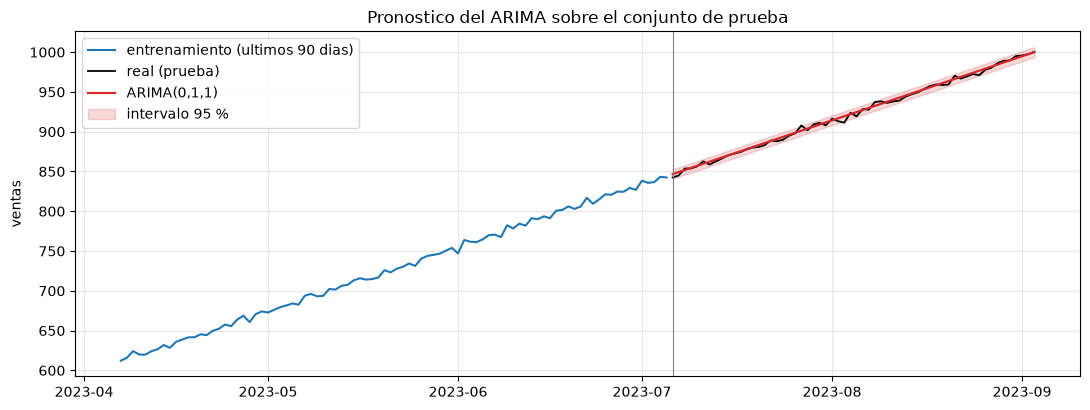

In [10]:
pronostico = modelo.get_forecast(steps=len(prueba))
pred_arima = pronostico.predicted_mean
intervalo = pronostico.conf_int(alpha=0.05)
inferior, superior = intervalo.iloc[:, 0], intervalo.iloc[:, 1]

tabla = pd.DataFrame({
    "ultimo valor": metricas(prueba, pred_ultimo),
    "deriva": metricas(prueba, pred_deriva),
    "ARIMA(0,1,1)": metricas(prueba, pred_arima),
}).T
print("Desempeno en los 60 dias de prueba:")
print(tabla.to_string())

dentro = (prueba.values >= inferior.values) & (prueba.values <= superior.values)
print()
print("Dias reales dentro del intervalo del 95 %:", int(dentro.sum()), "de", len(prueba), "->", round(float(dentro.mean() * 100), 1), "%")
print("Ancho del intervalo: primer dia", round(float(superior.iloc[0] - inferior.iloc[0]), 1),
      "| ultimo dia", round(float(superior.iloc[-1] - inferior.iloc[-1]), 1))

error_arima = prueba.values - pred_arima.values
print("Error medio (sesgo) del ARIMA:", round(float(error_arima.mean()), 2),
      "| desviacion del error:", round(float(error_arima.std()), 2))

fig, eje = plt.subplots(figsize=(11, 4.2))
eje.plot(entrenamiento.index[-90:], entrenamiento.values[-90:], color="tab:blue", label="entrenamiento (ultimos 90 dias)")
eje.plot(prueba.index, prueba.values, color="black", linewidth=1.3, label="real (prueba)")
eje.plot(prueba.index, pred_arima.values, color="tab:red", linewidth=1.6, label="ARIMA(0,1,1)")
eje.fill_between(prueba.index, inferior.values, superior.values, color="tab:red", alpha=0.18, label="intervalo 95 %")
eje.axvline(prueba.index[0], color="gray", linewidth=0.8)
eje.set_title("Pronostico del ARIMA sobre el conjunto de prueba")
eje.set_ylabel("ventas")
eje.legend(loc="upper left")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Para saber si la mejora del ARIMA sobre la deriva es real o solo azar de estos 60 dias, se compara el error absoluto de ambos dia por dia (comparacion pareada): se calcula la diferencia media y su error estandar.

In [11]:
dif = np.abs(prueba.values - pred_deriva) - np.abs(error_arima)   # positivo = el ARIMA se equivoca menos ese dia
media_dif = dif.mean()
ee_dif = dif.std(ddof=1) / np.sqrt(len(dif))
print("Dias en que el ARIMA se equivoca menos que la deriva:", int((dif > 0).sum()), "de", len(dif))
print("Diferencia media del error absoluto (deriva - ARIMA):", round(float(media_dif), 3), "+/-", round(float(ee_dif), 3), "(error estandar)")
print("Cociente diferencia / error estandar:", round(float(media_dif / ee_dif), 2))

Dias en que el ARIMA se equivoca menos que la deriva: 30 de 60
Diferencia media del error absoluto (deriva - ARIMA): 0.186 +/- 0.246 (error estandar)
Cociente diferencia / error estandar: 0.76


### Conclusiones del Bloque 5

En los 60 dias de prueba el `ARIMA(0,1,1)` obtiene MAE 2,26, RMSE 2,80 y MAPE 0,25 %, frente a MAE 2,44, RMSE 3,10 y MAPE 0,26 % de la deriva y MAE 80,15 de repetir el ultimo valor. El intervalo del 95 % contiene 58 de los 60 dias reales (96,7 %), con un ancho de unas 12 ventas, asi que su cobertura es la esperada. El error medio es -0,75 (sesgo pequeno) con una desviacion de 2,7, cercana al ruido de la serie (2,95).

Sin embargo, la mejora sobre la deriva **no es distinguible del azar**: el ARIMA se equivoca menos en 30 de 60 dias y la diferencia media (0,19) es solo 0,76 errores estandar. La lectura honesta es que ARIMA y deriva rinden practicamente igual, porque la serie es una recta con ruido y ambos estiman esa recta. El aporte del ARIMA es un modelo formal, con intervalos de confianza calibrados, que se puede guardar y reutilizar.

## Bloque 6: modelo final, pronostico para la bodega y guardado

Con la evaluacion ya hecha, el modelo que se entrega se vuelve a ajustar con **toda** la serie (366 dias), porque los dias mas recientes son los mas utiles para pronosticar el futuro. El orden `(0,1,1)` con constante no se vuelve a elegir: es el que se decidio con el entrenamiento. Se pronostican los proximos 90 dias (unos tres meses, el horizonte para dimensionar la bodega) y se guarda el modelo en la carpeta `models/`. Para comprobar el guardado, se recarga el archivo y se verifica que da exactamente el mismo pronostico.

Parametros del modelo final (toda la serie):
x1        2.5988
ma.L1    -0.9639
sigma2    8.8320
Parametros del modelo de entrenamiento, para comparar:
x1        2.5991
ma.L1    -0.9450
sigma2    9.0631

Pronostico (ultimo dato real: 2023-09-03 = 1000.5 )
                     pronostico  inferior 95 %  superior 95 %
dia 1 (2023-09-04)       1002.1          996.3         1008.0
dia 30 (2023-10-03)      1077.5         1071.6         1083.4
dia 60 (2023-11-02)      1155.5         1149.4         1161.5
dia 90 (2023-12-02)      1233.4         1227.3         1239.6
Aumento esperado de las ventas diarias en 90 dias: 232.9


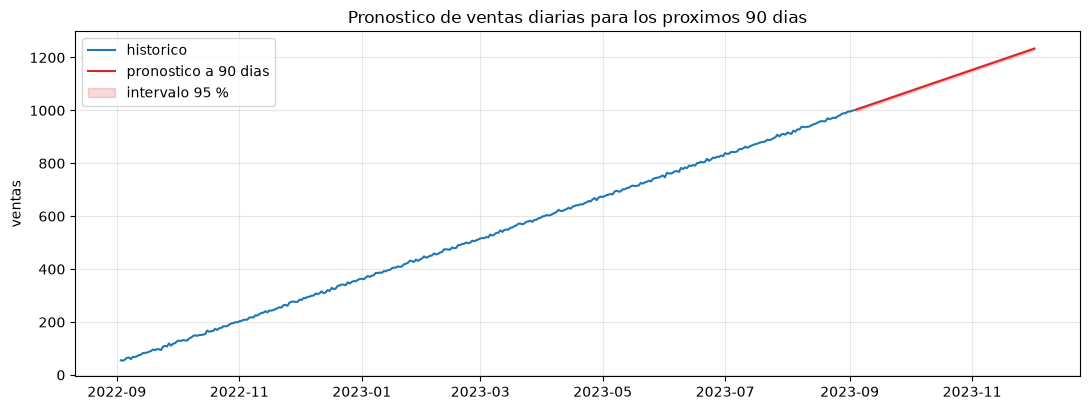

In [12]:
modelo_final = ARIMA(ventas, order=(P, 1, Q), trend="t").fit()
print("Parametros del modelo final (toda la serie):")
print(modelo_final.params.round(4).to_string())
print("Parametros del modelo de entrenamiento, para comparar:")
print(modelo.params.round(4).to_string())

HORIZONTE = 90
futuro = modelo_final.get_forecast(steps=HORIZONTE)
pred_futuro = futuro.predicted_mean
int_futuro = futuro.conf_int(alpha=0.05)

print()
print("Pronostico (ultimo dato real:", ventas.index[-1].date(), "=", round(float(ventas.iloc[-1]), 1), ")")
resumen = pd.DataFrame({
    "pronostico": pred_futuro,
    "inferior 95 %": int_futuro.iloc[:, 0],
    "superior 95 %": int_futuro.iloc[:, 1],
}).iloc[[0, 29, 59, 89]].round(1)
resumen.index = [f"dia {n} ({f.date()})" for n, f in zip([1, 30, 60, 90], resumen.index)]
print(resumen.to_string())
print("Aumento esperado de las ventas diarias en 90 dias:", round(float(pred_futuro.iloc[-1] - ventas.iloc[-1]), 1))

fig, eje = plt.subplots(figsize=(11, 4.2))
eje.plot(ventas.index, ventas.values, color="tab:blue", label="historico")
eje.plot(pred_futuro.index, pred_futuro.values, color="tab:red", label="pronostico a 90 dias")
eje.fill_between(pred_futuro.index, int_futuro.iloc[:, 0].values, int_futuro.iloc[:, 1].values,
                 color="tab:red", alpha=0.18, label="intervalo 95 %")
eje.set_title("Pronostico de ventas diarias para los proximos 90 dias")
eje.set_ylabel("ventas")
eje.legend(loc="upper left")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
import os
from statsmodels.tsa.arima.model import ARIMAResults

os.makedirs("../models", exist_ok=True)
ruta = "../models/arima_011_deriva_ventas_diarias.pkl"
modelo_final.save(ruta)
print("Modelo guardado en:", ruta, "|", round(os.path.getsize(ruta) / 1024, 1), "KB")

recargado = ARIMAResults.load(ruta)
pred_recargado = recargado.get_forecast(steps=HORIZONTE).predicted_mean
print("El modelo recargado da el mismo pronostico:", bool(np.allclose(pred_recargado.values, pred_futuro.values)))
print("Orden del modelo recargado:", recargado.model.order, "| constante:", recargado.model.trend)

Modelo guardado en: ../models/arima_011_deriva_ventas_diarias.pkl | 879.2 KB
El modelo recargado da el mismo pronostico: True
Orden del modelo recargado: (0, 1, 1) | constante: t


### Conclusiones finales del proyecto

- **Serie:** ventas diarias (366 dias, 2022-09-03 a 2023-09-03), sin nulos ni huecos. Una recta de 2,6 ventas por dia explica el 99,99 % de su variacion; el ruido alrededor de esa recta es de unas 3 ventas (0,56 % de la media) y es estable.
- **Respuestas a las preguntas del enunciado:** el "tensor" (frecuencia) es diario; hay tendencia creciente casi lineal; la serie original no es estacionaria pero su primera diferencia si (d = 1); hay ruido pequeno y sin memoria, con un indicio semanal muy debil que no justifica estacionalidad.
- **Modelo:** `ARIMA(0,1,1)` con constante, elegido solo con el entrenamiento por AIC con una regla de parsimonia fijada de antemano. En 60 dias de prueba logra MAPE 0,25 % y su intervalo del 95 % cubre el 96,7 % de los dias, pero no es distinguible de la simple extrapolacion de una recta (deriva).
- **Pronostico:** ver la tabla del Bloque 6 para el volumen esperado a 30, 60 y 90 dias con su intervalo.
- **Limitaciones:** hay un solo ano de datos y ninguna observacion de estacionalidad anual ni de cambios de ritmo; el modelo asume que el crecimiento lineal continua. El intervalo del 95 % (unas 12 ventas de ancho, casi constante en el horizonte) refleja el ruido diario con los parametros estimados dados; no incluye la incertidumbre de la pendiente (error estandar de 0,01 por dia, unas 2 ventas a 90 dias) ni un cambio estructural (una promocion, una crisis, un nuevo competidor). Conviene reajustar el modelo cuando haya mas datos.